# Homework 5 solutions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg

## 1. Linear least squares

(a) The pseudo-inverse gives the parameters as
$$\mathbf{a} = \mathbf{V}\mathbf{S}^{-1}\mathbf{U^T}\mathbf{d}.$$
Write this in component form
$$a_i = \sum_{j,k,m} V_{ij}(S^{-1})_{jk}(U^T)_{km} d_m.$$
Since $\mathbf{S}$ is diagonal, its inverse is also diagonal with elements $1/s_i$. We can also remove the transpose on $\mathbf{U}$ in the sum by flipping the indices. Therefore
$$a_i = \sum_{j,k,m} V_{ij}{\delta_{jk}\over s_j}U_{mk} d_m = \sum_{j,m} {U_{mj}d_m\over s_j} V_{ij}.$$
The $i$th component of volumn vector $\alpha$ of the matrix $\mathbf{V}$ corresponds to $V_{i\alpha}$ (fix the second label which identifies the column and then take the $i$th row), and similarly for the column vectors of $\mathbf{U}$. Therefore we can write (changing the label $j$ to $\alpha$)

$$a_i = \sum_{j,m} {U_{mj}d_m\over s_j} V_{ij}= \sum_{\alpha,m} {(\mathbf{u}_\alpha)_m d_m\over s_\alpha} (v_\alpha)_i = \sum_\alpha c_\alpha \times (\mathbf{v}_\alpha)_i$$
with
$$c_\alpha = \sum_m {(\mathbf{u}_\alpha)_m d_m\over s_\alpha}.$$ 
Putting this back into vector notation gives equations (1) and (2) in the question.

(b)

Condition number = 71.2262999382665


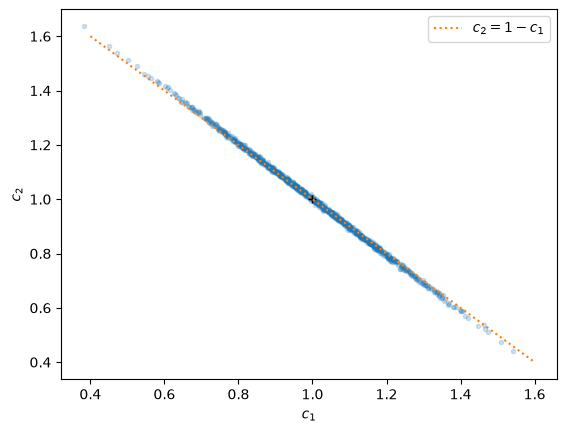

In [2]:
n = 10 # number of measurements
sigma = 0.01 # measurement error
r1, r2 = 1, 1.1  # decay rates

# measurement points
x = np.linspace(0,1,n)
# true function
y_true = np.exp(-r1*x) + np.exp(-r2*x)

# design matrix
# it's simpler to first calculate A^T and then 
# take the transpose of that to get A
A = np.zeros((2, n))
A[:] = [np.exp(-r1*x), np.exp(-r2*x)]
A = A.T / sigma
print("Condition number =", np.linalg.cond(A))

# SVD
U, Sdiag, VT = np.linalg.svd(A,full_matrices=False)

def do_fit():
    # Generate a data set by adding noise to the true function
    y = (y_true + np.random.normal(scale=sigma, size=n)) / sigma
    # Get the fitted parameters from the sum in part (a)
    a = np.zeros(2)
    for i in range(2):
        a = a + (U[:,i]@y / Sdiag[i]) * VT[i,:]
    return a

ntrials = 1000

avec = np.zeros((ntrials,2))
for j in range(ntrials):
    avec[j,:] = do_fit()
plt.plot(avec[:,0], avec[:,1], '.', alpha=0.2)

plt.plot((1,), (1,), 'k+')
c = np.linspace(0.4,1.6,10)
plt.plot(c,c[::-1],":",label=r'$c_2=1-c_1$')

plt.ylabel(r'$c_2$')
plt.xlabel(r'$c_1$')
plt.legend()
plt.show()

(c) The right singular vectors are very close to $(1,1)$ and $(1,-1)$ (see next cell). The first one has a large singular value, so the combination $c_1+c_2$ is well-constrained. The second singular value is much smaller (by about a factor of 100) showing that the difference $c_1-c_2$ is not well-constrained. We see this in the plot above where the points lie close to the line $c_1+c_2=1$, but have a wide dispersion along the line.

In [3]:
print('Singular values:', Sdiag)

# Print out the right singular vectors 
#(removing overall normalization
print("Right singular vectors:", VT * np.sqrt(2))


Singular values: [294.68740274   4.13733976]
Right singular vectors: [[-1.01506318 -0.98470643]
 [ 0.98470643 -1.01506318]]


## 2. Fitting planetary orbits

In [4]:
def rv(t, P, a):
    # Calculates the radial velocity of a star orbited by a planet
    # at the times in the vector t
    
    # extract the orbit parameters
    # P, t and tp in days, mp in Jupiter masses, v0 in m/s  
    mp, e, omega, tp, v0 = a
        
    # mean anomaly
    M = 2*np.pi * (t-tp) / P
    
    # velocity amplitude
    K = 204 * P**(-1/3) * mp  / np.sqrt(1.0-e**2) # m/s
    
    # solve Kepler's equation for the eccentric anomaly E - e * np.sin(E) = M
    # Iterative method from Heintz DW, "Double stars", Reidel, 1978
    # first guess
    E = M + e*np.sin(M)  + ((e**2)*np.sin(2*M)/2)
    while True:
        E0 = E 
        M0 = E0 - e*np.sin(E0)
        E = E0 + (M-M0)/(1.0 - e*np.cos(E0))
        if np.max(np.abs((E-E0))) < 1e-6:
            break
        
    # evaluate the velocities
    theta = 2.0 * np.arctan( np.sqrt((1+e)/(1-e)) * np.tan(E/2))
    vel = v0 + K * ( np.cos(theta + omega) + e * np.cos(omega))
    
    return vel

In [5]:
def rv_model(t, P, a):
    v = rv(t, P, a)
    A =  np.zeros([len(t), len(a)])
    eps = 1e-8
    b = np.copy(a) * (1 + eps)
    v0 = rv(t, P, np.array([b[0],a[1],a[2],a[3],a[4]]))
    v1 = rv(t, P, np.array([a[0],b[1],a[2],a[3],a[4]]))
    v2 = rv(t, P, np.array([a[0],a[1],b[2],a[3],a[4]]))
    v3 = rv(t, P, np.array([a[0],a[1],a[2],b[3],a[4]]))
    v4 = rv(t, P, np.array([a[0],a[1],a[2],a[3],b[4]]))
    A[:, 0] = (v0 - v) / (b[0]-a[0])
    A[:, 1] = (v1 - v) / (b[1]-a[1])
    A[:, 2] = (v2 - v) / (b[2]-a[2])
    A[:, 3] = (v3 - v) / (b[3]-a[3])
    A[:, 4] = (v4 - v) / (b[4]-a[4])
    return v, A

In [6]:
# Observations
# These are for HD145675 from Butler et al. 2003
tobs, vobs, eobs = np.loadtxt('rvs.txt', unpack=True)

# initial guess
# P, mp, e, omega, tp, v0 
P = 1724
a0 = np.array([10.0, 0.3, 0.1, 1e-3, 1e-3])

a = a0
err = 1.0
lam = 1e-3
while err > 1e-6:
    v, A = rv_model(tobs, P, a)
    A[:, 0] = A[:, 0] / eobs
    A[:, 1] = A[:, 1] / eobs
    A[:, 2] = A[:, 2] / eobs
    A[:, 3] = A[:, 3] / eobs
    A[:, 4] = A[:, 4] / eobs
    r = (v-vobs)/eobs
    lhs = A.T@A
    lhs = lhs@(np.identity(len(a))*(1+lam))
    rhs = -A.T@r
    da = np.linalg.inv(lhs)@rhs
    # artificially reduce the step to not overshoot e=1
    a1 = a + 0.2*da
    #print(a1, a)
    v1, A1 = rv_model(tobs, P, a1)
    A1[:, 0] = A1[:, 0] / eobs
    A1[:, 1] = A1[:, 1] / eobs
    A1[:, 2] = A1[:, 2] / eobs
    A1[:, 3] = A1[:, 3] / eobs
    A1[:, 4] = A1[:, 4] / eobs
    r1 = (v1-vobs)/eobs
    err = np.sum(r**2)
    err1 = np.sum(r1**2)
    print("err = %lg, a=(%lg, %lg, %lg, %lg, %lg), lam = %lg" % (err1 ,a1[0], a1[1], a1[2], a1[3], a1[4], lam))
    if err1 > err:
        lam = lam * 10
    else:
        lam = lam / 10
        a = a1
        if (err-err1) < 0.1:
            break

print("Best-fit parameters: M = %lg, e = %lg, omega = %lg, tP = %lg, v0 = %lg " % 
      (a[0], a[1], a[2] % np.pi, a[3], a[4]))

err = 72886.8, a=(8.00827, 0.271521, 0.30115, 29.4316, -4.85519), lam = 0.001
err = 48854, a=(6.48856, 0.233148, 0.551196, 64.8671, -8.90329), lam = 0.0001
err = 33043.9, a=(5.37886, 0.180175, 0.836134, 101.678, -12.4339), lam = 1e-05
err = 22365.4, a=(4.64014, 0.108496, 1.10353, 127.206, -15.5443), lam = 1e-06
err = 15112.9, a=(4.21818, 0.023106, 1.18218, 100.234, -18.1062), lam = 1e-07
err = 12449.7, a=(4.02284, -0.0508543, -1.10151, -570.281, -20.0752), lam = 1e-08
err = 8387.51, a=(3.95834, 0.0556116, -1.15878, -624.772, -21.6418), lam = 1e-09
err = 5852.24, a=(3.99346, 0.128072, -0.0300392, -345.706, -22.8229), lam = 1e-10
err = 3798.06, a=(4.0854, 0.182493, -0.162904, -405.8, -23.8898), lam = 1e-11
err = 2463.45, a=(4.19423, 0.229393, -0.0883558, -403.591, -24.7424), lam = 1e-12
err = 1602.69, a=(4.30176, 0.262999, -0.0139533, -397.076, -25.4412), lam = 1e-13
err = 1050.19, a=(4.39895, 0.287277, 0.0455681, -391.326, -26.0144), lam = 1e-14
err = 696.252, a=(4.48284, 0.305132, 0.09

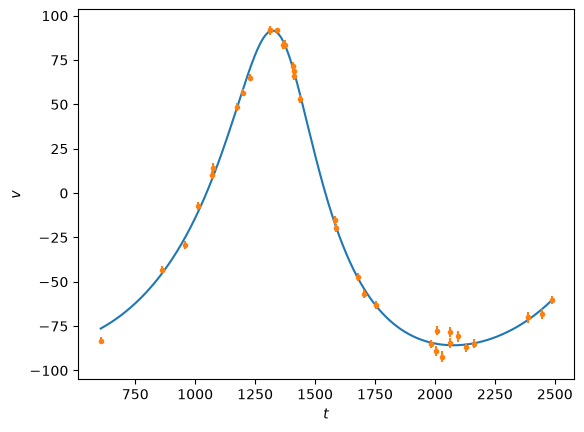

In [7]:
t = np.linspace(tobs[0], tobs[-1], 1000)
plt.plot(t, rv(t,P, a), 'C0')
plt.plot(tobs, vobs, 'C1.')
plt.errorbar(tobs, vobs, eobs, fmt='none', ecolor='C1')
plt.ylabel(r'$v$')
plt.xlabel(r'$t$')
plt.show()

## 3. Photon random walk

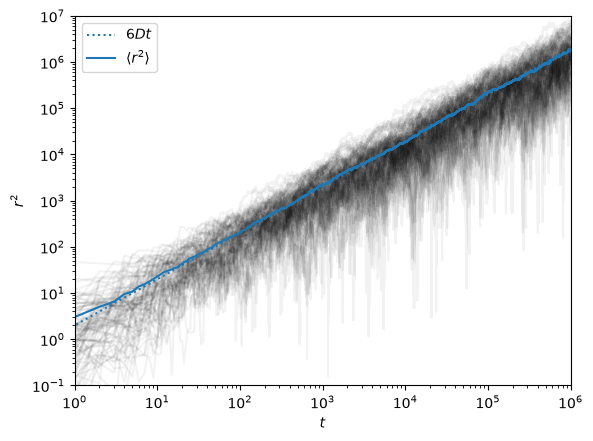

In [8]:
seed = 7768
rng = np.random.default_rng(seed)

plt.close('all')

def photon(nsteps):
    # integrate the random walk for nsteps
    # start at the origin
    x = y = z = 0

    # random steps
    dist = rng.uniform(size = nsteps)
    dist = - np.log(dist)
    mu = -1 + 2*rng.uniform(size = nsteps)
    phi = rng.uniform(size = nsteps)

    svec = np.sqrt(1 - mu*mu)
    dx = dist * svec * np.cos(2*np.pi*phi)
    dy = dist * svec * np.sin(2*np.pi*phi)
    dz = dist * mu
    
    x = np.cumsum(dx)
    y = np.cumsum(dy)
    z = np.cumsum(dz)
    r2 = x**2 + y**2 + z**2

    return x, r2


# First run 30 trials and plot r^2 and <r^2>
ntrials = 10**2
nsteps = 10**6

r2av = np.zeros(nsteps)
t = np.arange(nsteps)
xf = np.zeros(ntrials)

for j in range(ntrials):

    x,r2 = photon(nsteps)        
    plt.plot(t,r2,'k',alpha=0.05)

    r2av += r2
    xf[j] = x[-1]

r2av = r2av/ntrials

# Plot the indvidual trajectories and the mean
# The expected diffusion coefficient is 1/3
Dpred = 1/3
plt.yscale('log')
plt.xscale('log')
plt.ylim([1e-1,10*nsteps])
plt.xlim([1,nsteps])
plt.plot(t,6*Dpred*t,'C0:',label=r'$6Dt$')
plt.plot(t,r2av,'C0',label=r'$\langle r^2\rangle$')
plt.xlabel(r'$t$')
plt.ylabel(r'$r^2$')
plt.legend(loc='upper left')
plt.show()

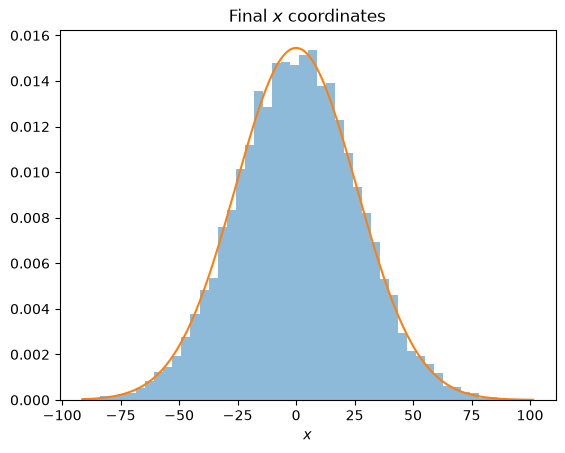

In [9]:
# Now do a smaller number of steps but a large number of trials
ntrials = 10**4
nsteps = 1000

xf = np.zeros(ntrials)

for j in range(ntrials):
    x,r2 = photon(nsteps)        
    xf[j] = x[-1]

# Plot the histogram of final x positions and compare with the
# diffusion equation Green's function 
xx = np.linspace(xf.min(), xf.max(), 200)
plt.hist(xf, bins=50, density=True, alpha=0.5)
Dpred = 1/3
t = nsteps
plt.plot(xx, np.exp(-xx**2/(4*Dpred*t)) / np.sqrt(4*np.pi*Dpred*t))
plt.xlabel('$x$')
plt.title(r'Final $x$ coordinates')
plt.show()